## 06 — Testing Dataset Preparation
### 1. Introduction
This notebook focuses on preparing an independent testing dataset for the Metadata-Filtered RAG project using the MS COCO 2017 dataset.

The testing dataset is created from the official COCO validation annotations (val2017). It contains 100 selected images, their human-written reference captions, and their corresponding object annotations.

The main objective is to prepare clean and structured testing data that will be used later to evaluate the Metadata-Filtered RAG system.

The testing images are kept separate from the training and validation images to avoid data leakage.

## 1. Data Exploration

### 1.1 Import Libraries

Import the required Python libraries for data exploration,
annotation processing, image verification, and data analysis.


In [1]:
import json
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


### 1.2 Define Project Paths

Define the paths of the COCO validation annotations,
the testing images, and the testing output directory.

In [2]:
# Project directory
PROJECT_DIR = Path(r"C:\Users\PC\Desktop\Metadata_RAG_START")

# Main directories
ANNOTATIONS_DIR = PROJECT_DIR / "annotations"
IMAGES_DIR = PROJECT_DIR / "images"
DATA_DIR = PROJECT_DIR / "data"

# Testing source images
TEST_SOURCE_DIR = IMAGES_DIR / "testing_images"

# COCO validation annotations
CAPTIONS_PATH = ANNOTATIONS_DIR / "captions_val2017.json"
INSTANCES_PATH = ANNOTATIONS_DIR / "instances_val2017.json"

# Testing output directory
TESTING_DATA_DIR = DATA_DIR / "testing"
TESTING_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Display paths
print("Project directory:", PROJECT_DIR)
print("Testing images directory:", TEST_SOURCE_DIR)
print("Captions annotations:", CAPTIONS_PATH)
print("Instances annotations:", INSTANCES_PATH)
print("Testing output directory:", TESTING_DATA_DIR)

Project directory: C:\Users\PC\Desktop\Metadata_RAG_START
Testing images directory: C:\Users\PC\Desktop\Metadata_RAG_START\images\testing_images
Captions annotations: C:\Users\PC\Desktop\Metadata_RAG_START\annotations\captions_val2017.json
Instances annotations: C:\Users\PC\Desktop\Metadata_RAG_START\annotations\instances_val2017.json
Testing output directory: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing


### 1.3 Load COCO Annotations

Load the captions and object instance annotations
from the COCO 2017 validation dataset.

In [4]:
# Verify required files
required_paths = [
    CAPTIONS_PATH,
    INSTANCES_PATH,
    TEST_SOURCE_DIR
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Required path not found: {path}")

# Load captions annotations
with open(CAPTIONS_PATH, "r", encoding="utf-8") as f:
    captions_data = json.load(f)

# Load object annotations
with open(INSTANCES_PATH, "r", encoding="utf-8") as f:
    instances_data = json.load(f)

print("COCO annotations loaded successfully!")

print("\nCaptions information:")
print("Images:", len(captions_data["images"]))
print("Captions:", len(captions_data["annotations"]))

print("\nInstances information:")
print("Images:", len(instances_data["images"]))
print("Object annotations:", len(instances_data["annotations"]))
print("Categories:", len(instances_data["categories"]))

COCO annotations loaded successfully!

Captions information:
Images: 5000
Captions: 25014

Instances information:
Images: 5000
Object annotations: 36781
Categories: 80


### 1.4 Explore Caption Annotations

Examine the structure of the captions and display
some examples of human-written descriptions.

In [5]:
# Convert captions into a DataFrame
captions_df = pd.DataFrame(captions_data["annotations"])

# Display dataset information
print("Caption dataset shape:", captions_df.shape)

# Display first captions
display(captions_df[["image_id", "caption"]].head(10))

# Count captions per image
captions_per_image = captions_df.groupby("image_id").size()

print("\nCaptions per image:")
print(captions_per_image.describe())

print("\nNumber of images with captions:", captions_per_image.count())

Caption dataset shape: (25014, 3)


,image_id,caption
0,179765,A black Honda motorcycle parked in front of a ...
1,179765,A Honda motorcycle parked in a grass driveway
2,190236,An office cubicle with four different types of...
3,331352,A small closed toilet in a cramped space.
4,517069,Two women waiting at a bench next to a street.
5,179765,A black Honda motorcycle with a dark burgundy ...
6,331352,A tan toilet and sink combination in a small r...
7,190236,The home office space seems to be very cluttered.
8,182417,A beautiful dessert waiting to be shared by tw...
9,517069,A woman sitting on a bench and a woman standin...



Captions per image:
count    5000.000000
mean        5.002800
std         0.056505
min         5.000000
25%         5.000000
50%         5.000000
75%         5.000000
max         7.000000
dtype: float64

Number of images with captions: 5000


### 1.5 Explore Object Annotations

Explore the object annotations, category names,
and the number of objects associated with images.

In [6]:
# Convert object annotations into DataFrames
objects_df = pd.DataFrame(instances_data["annotations"])
categories_df = pd.DataFrame(instances_data["categories"])

# Map category IDs to category names
category_mapping = dict(
    zip(categories_df["id"], categories_df["name"])
)

objects_df["category_name"] = objects_df["category_id"].map(category_mapping)

print("Object annotations shape:", objects_df.shape)
print("Number of categories:", len(categories_df))

# Display object categories
display(categories_df.head(10))

# Most frequent object categories
category_counts = objects_df["category_name"].value_counts()

print("\nTop 10 object categories:")
display(category_counts.head(10).to_frame("count"))

# Number of objects per image
objects_per_image = objects_df.groupby("image_id").size()

print("\nObjects per image:")
print(objects_per_image.describe())

Object annotations shape: (36781, 8)
Number of categories: 80


,supercategory,id,name
0,person,1,person
1,vehicle,2,bicycle
2,vehicle,3,car
3,vehicle,4,motorcycle
4,vehicle,5,airplane
5,vehicle,6,bus
6,vehicle,7,train
7,vehicle,8,truck
8,vehicle,9,boat
9,outdoor,10,traffic light



Top 10 object categories:


,count
category_name,
person,11004
car,1932
chair,1791
book,1161
bottle,1025
cup,899
dining table,697
traffic light,637
bowl,626



Objects per image:
count    4952.000000
mean        7.427504
std         7.439434
min         1.000000
25%         2.000000
50%         4.000000
75%        10.000000
max        63.000000
dtype: float64


### 1.6 Verify Testing Images

Check the number of downloaded images and compare
their image IDs with the COCO validation annotations.

In [7]:
# List downloaded JPG images
testing_image_files = list(TEST_SOURCE_DIR.glob("*.jpg"))

# Extract image IDs from COCO filenames
testing_image_ids = set()

for image_path in testing_image_files:
    try:
        image_id = int(image_path.stem)
        testing_image_ids.add(image_id)
    except ValueError:
        print("Invalid image filename:", image_path.name)

# Get available IDs from COCO annotations
coco_image_ids = {
    image["id"] for image in captions_data["images"]
}

# Compare downloaded images with annotations
matched_ids = testing_image_ids.intersection(coco_image_ids)
unmatched_ids = testing_image_ids - coco_image_ids

print("Downloaded images:", len(testing_image_files))
print("Valid image IDs:", len(testing_image_ids))
print("Images with matching COCO annotations:", len(matched_ids))
print("Images without matching captions annotations:", len(unmatched_ids))

print("\nExpected number of testing images: 1000")

Downloaded images: 1000
Valid image IDs: 1000
Images with matching COCO annotations: 1000
Images without matching captions annotations: 0

Expected number of testing images: 1000


### 1.7 Check Missing Annotations

Identify testing images that have no captions
or no object annotations.

In [8]:
# IDs with captions
caption_image_ids = set(captions_df["image_id"].unique())

# IDs with object annotations
object_image_ids = set(objects_df["image_id"].unique())

# Check missing annotations among downloaded images
missing_caption_ids = matched_ids - caption_image_ids
missing_object_ids = matched_ids - object_image_ids

print("Images without captions:", len(missing_caption_ids))
print("Images without object annotations:", len(missing_object_ids))

print("\nData exploration completed.")

Images without captions: 0
Images without object annotations: 10

Data exploration completed.


## 2. Data Quality Assessment
Objectif : vérifier la qualité et la cohérence des données avant leur utilisation.
### 2.1 Verify Image Files

Check the existence, format, and readability of
the downloaded testing images.

In [24]:
valid_images = []
corrupted_images = []
invalid_images = []

for image_path in TEST_SOURCE_DIR.glob("*.jpg"):
    try:
        with Image.open(image_path) as img:
            img.verify()

        with Image.open(image_path) as img:
            if img.format == "JPEG":
                valid_images.append(image_path.name)
            else:
                invalid_images.append(image_path.name)

    except Exception:
        corrupted_images.append(image_path.name)

print("Total images checked:", len(valid_images)
      + len(corrupted_images) + len(invalid_images))

print("Valid JPEG images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))
print("Invalid format images:", len(invalid_images))

Total images checked: 1000
Valid JPEG images: 1000
Corrupted images: 0
Invalid format images: 0


### 2.2 Detect Duplicate Images

Identify images with identical file content
using their MD5 hashes.

In [25]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for image_name in valid_images:
    image_path = TEST_SOURCE_DIR / image_name

    with open(image_path, "rb") as f:
        image_hash = hashlib.md5(f.read()).hexdigest()

    hash_groups[image_hash].append(image_name)

duplicate_groups = [
    names for names in hash_groups.values()
    if len(names) > 1
]

print("Duplicate groups:", len(duplicate_groups))

for group in duplicate_groups:
    print(group)

Duplicate groups: 0


### 2.3 Check Missing and Empty Captions

Identify missing, null, or empty captions
in the testing dataset.

In [26]:
# Select captions belonging to testing images
testing_captions_df = captions_df[
    captions_df["image_id"].isin(matched_ids)
].copy()

# Check missing and empty captions
missing_captions = testing_captions_df["caption"].isna().sum()

empty_captions = (
    testing_captions_df["caption"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("Total testing captions:", len(testing_captions_df))
print("Missing captions:", missing_captions)
print("Empty captions:", empty_captions)

Total testing captions: 5002
Missing captions: 0
Empty captions: 0


### 2.4 Clean Caption Data

Remove missing and empty captions, normalize whitespace,
and remove duplicate captions for the same image.

In [27]:
# Remove missing captions
cleaned_captions_df = testing_captions_df.dropna(
    subset=["caption"]
).copy()

# Normalize whitespace
cleaned_captions_df["caption"] = (
    cleaned_captions_df["caption"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Remove empty captions
cleaned_captions_df = cleaned_captions_df[
    cleaned_captions_df["caption"] != ""
].copy()

# Remove duplicate captions for the same image
cleaned_captions_df = cleaned_captions_df.drop_duplicates(
    subset=["image_id", "caption"]
)

cleaned_captions_df = cleaned_captions_df.reset_index(drop=True)

print("Original captions:", len(testing_captions_df))
print("Cleaned captions:", len(cleaned_captions_df))
print("Removed captions:", 
      len(testing_captions_df) - len(cleaned_captions_df))

Original captions: 5002
Cleaned captions: 5001
Removed captions: 1


### 2.5 Verify Captions Distribution

Check the number of captions associated with each testing image
and identify images with fewer or more than five captions.

In [28]:
# Count captions per image after cleaning
cleaned_captions_per_image = (
    cleaned_captions_df.groupby("image_id").size()
)

# Identify images with different caption counts
less_than_five = cleaned_captions_per_image[
    cleaned_captions_per_image < 5
]

more_than_five = cleaned_captions_per_image[
    cleaned_captions_per_image > 5
]

print("Images with exactly 5 captions:",
      (cleaned_captions_per_image == 5).sum())

print("Images with fewer than 5 captions:", len(less_than_five))
print("Images with more than 5 captions:", len(more_than_five))

print("\nCaption count distribution:")
print(cleaned_captions_per_image.value_counts().sort_index())

print("\nImages with fewer than 5 captions:")
display(less_than_five)

print("\nImages with more than 5 captions:")
display(more_than_five)

Images with exactly 5 captions: 997
Images with fewer than 5 captions: 1
Images with more than 5 captions: 2

Caption count distribution:
4      1
5    997
6      2
Name: count, dtype: int64

Images with fewer than 5 captions:


image_id
211825    4
dtype: int64


Images with more than 5 captions:


image_id
215259    6
328030    6
dtype: int64

### 2.6 Verify Object Annotations

Check the object annotations associated with the testing images.
Identify images without object annotations and preserve their records.

In [29]:
# Select object annotations for testing images
testing_objects_df = objects_df[
    objects_df["image_id"].isin(matched_ids)
].copy()

# Count objects per image
testing_objects_per_image = (
    testing_objects_df.groupby("image_id").size()
)

# Identify images without object annotations
images_without_objects = (
    matched_ids - set(testing_objects_per_image.index)
)

print("Total testing images:", len(matched_ids))
print("Images with object annotations:",
      len(testing_objects_per_image))
print("Images without object annotations:",
      len(images_without_objects))
print("Total object annotations:", len(testing_objects_df))

print("\nImages without object annotations:")
print(sorted(images_without_objects))

Total testing images: 1000
Images with object annotations: 990
Images without object annotations: 10
Total object annotations: 7375

Images without object annotations:
[42888, 58636, 173183, 261796, 278006, 312549, 330554, 370999, 447789, 502910]


### 2.7 Verify Bounding Boxes

Check the validity of object bounding boxes
using image dimensions and COCO annotation coordinates.

In [30]:
# COCO bounding boxes use [x, y, width, height]
valid_boxes = []
invalid_boxes = []

image_dimensions = {
    image["id"]: (image["width"], image["height"])
    for image in captions_data["images"]
}

for _, row in testing_objects_df.iterrows():
    x, y, width, height = row["bbox"]
    image_width, image_height = image_dimensions[row["image_id"]]

    is_valid = (
        width > 0
        and height > 0
        and x >= 0
        and y >= 0
        and x + width <= image_width + 1
        and y + height <= image_height + 1
    )

    if is_valid:
        valid_boxes.append(row["id"])
    else:
        invalid_boxes.append(row["id"])

print("Total bounding boxes:", len(testing_objects_df))
print("Valid bounding boxes:", len(valid_boxes))
print("Invalid bounding boxes:", len(invalid_boxes))

Total bounding boxes: 7375
Valid bounding boxes: 7375
Invalid bounding boxes: 0


## 3 — Testing Dataset Preparation
Objectif : préparer les images, les annotations et les métadonnées nécessaires à l'évaluation.
### 3.1 RGB Image Preprocessing

Convert all valid testing images to RGB format
and save the processed images in the testing output directory.

In [31]:
# Create RGB output directory
RGB_DIR = TESTING_DATA_DIR / "testing_images_rgb"
RGB_DIR.mkdir(parents=True, exist_ok=True)

processed_rgb = []
rgb_errors = []

for image_name in valid_images:
    source_path = TEST_SOURCE_DIR / image_name
    output_path = RGB_DIR / image_name

    try:
        with Image.open(source_path) as img:
            rgb_image = img.convert("RGB")
            rgb_image.save(output_path, format="JPEG", quality=95)

        processed_rgb.append(image_name)

    except Exception as e:
        rgb_errors.append((image_name, str(e)))

print("RGB preprocessing completed!")
print("Processed images:", len(processed_rgb))
print("Errors:", len(rgb_errors))
print("Output directory:", RGB_DIR)

RGB preprocessing completed!
Processed images: 1000
Errors: 0
Output directory: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\testing_images_rgb


### 3.2 Grayscale Image Generation

Convert the original testing images to grayscale
and save the resulting images separately.

In [32]:
# Create grayscale output directory
GRAYSCALE_DIR = TESTING_DATA_DIR / "testing_images_grayscale"
GRAYSCALE_DIR.mkdir(parents=True, exist_ok=True)

processed_grayscale = []
grayscale_errors = []

for image_name in valid_images:
    source_path = TEST_SOURCE_DIR / image_name
    output_path = GRAYSCALE_DIR / image_name

    try:
        with Image.open(source_path) as img:
            grayscale_image = img.convert("L")
            grayscale_image.save(output_path, format="JPEG", quality=95)

        processed_grayscale.append(image_name)

    except Exception as e:
        grayscale_errors.append((image_name, str(e)))

print("Grayscale generation completed!")
print("Processed images:", len(processed_grayscale))
print("Errors:", len(grayscale_errors))
print("Output directory:", GRAYSCALE_DIR)

Grayscale generation completed!
Processed images: 1000
Errors: 0
Output directory: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\testing_images_grayscale


### 3.3 Extract Reference Captions and Object Annotations

Organize the human-written captions and object annotations
for each testing image.
Preserve the original reference captions for final evaluation.

In [33]:
# Keep original captions for evaluation
# Do not use the deduplicated captions for reference evaluation
testing_reference_captions = captions_df[
    captions_df["image_id"].isin(matched_ids)
].copy()

# Keep object annotations
testing_object_annotations = objects_df[
    objects_df["image_id"].isin(matched_ids)
].copy()

# Group captions by image
captions_by_image = (
    testing_reference_captions
    .groupby("image_id")["caption"]
    .apply(list)
    .to_dict()
)

# Group objects by image
objects_by_image = (
    testing_object_annotations
    .groupby("image_id")["category_name"]
    .apply(list)
    .to_dict()
)

print("Images with reference captions:", len(captions_by_image))
print("Images with object annotations:", len(objects_by_image))
print("Total original reference captions:", len(testing_reference_captions))
print("Total object annotations:", len(testing_object_annotations))

Images with reference captions: 1000
Images with object annotations: 990
Total original reference captions: 5002
Total object annotations: 7375


### 3.4 Create Testing Metadata

Combine image information, reference captions,
object categories, and bounding boxes into one metadata file.


In [34]:
# Image information from COCO
image_info = {
    image["id"]: image
    for image in captions_data["images"]
}

# Group bounding boxes by image
boxes_by_image = (
    testing_object_annotations
    .groupby("image_id")["bbox"]
    .apply(list)
    .to_dict()
)

metadata_records = []

for image_id in sorted(matched_ids):
    info = image_info[image_id]

    metadata_records.append({
        "image_id": image_id,
        "file_name": info["file_name"],
        "width": info["width"],
        "height": info["height"],
        "rgb_path": str(RGB_DIR / info["file_name"]),
        "grayscale_path": str(GRAYSCALE_DIR / info["file_name"]),
        "reference_captions": json.dumps(
            captions_by_image.get(image_id, []),
            ensure_ascii=False
        ),
        "num_captions": len(captions_by_image.get(image_id, [])),
        "object_categories": json.dumps(
            objects_by_image.get(image_id, []),
            ensure_ascii=False
        ),
        "num_objects": len(objects_by_image.get(image_id, [])),
        "bounding_boxes": json.dumps(
            boxes_by_image.get(image_id, []),
            ensure_ascii=False
        )
    })

metadata_df = pd.DataFrame(metadata_records)

print("Metadata shape:", metadata_df.shape)
display(metadata_df.head())

Metadata shape: (1000, 11)


,image_id,file_name,width,height,rgb_path,grayscale_path,reference_captions,num_captions,object_categories,num_objects,bounding_boxes
0,139,000000000139.jpg,640,426,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,"[""A woman stands in the dining area at the tab...",5,"[""potted plant"", ""tv"", ""tv"", ""chair"", ""chair"",...",20,"[[236.98, 142.51, 24.7, 69.5], [7.03, 167.76, ..."
1,632,000000000632.jpg,640,483,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,"[""Bedroom scene with a bookcase, blue comforte...",5,"[""bed"", ""potted plant"", ""book"", ""book"", ""book""...",18,"[[3.27, 266.85, 401.23, 208.25], [183.36, 136...."
2,802,000000000802.jpg,424,640,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,"[""A kitchen with a refrigerator, stove and ove...",5,"[""refrigerator"", ""oven""]",2,"[[245.05, 185.23, 165.76, 356.03], [33.08, 289..."
3,872,000000000872.jpg,621,640,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,"[""A couple of baseball player standing on a fi...",5,"[""sports ball"", ""person"", ""person"", ""baseball ...",4,"[[408.03, 172.04, 19.38, 16.53], [145.26, 100...."
4,1268,000000001268.jpg,640,427,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,C:\Users\PC\Desktop\Metadata_RAG_START\data\te...,"[""A beautiful woman taking a picture with her ...",5,"[""bird"", ""boat"", ""boat"", ""person"", ""person"", ""...",11,"[[192.81, 224.8, 74.73, 33.43], [124.77, 124.7..."


### 3.5 Save Testing Metadata

Save the testing metadata and image IDs
for future testing and evaluation.

In [35]:
# Save metadata CSV
METADATA_PATH = TESTING_DATA_DIR / "metadata_testing.csv"
metadata_df.to_csv(METADATA_PATH, index=False, encoding="utf-8-sig")

# Save testing image IDs
TESTING_IDS_PATH = TESTING_DATA_DIR / "testing_image_ids.json"

with open(TESTING_IDS_PATH, "w", encoding="utf-8") as f:
    json.dump(sorted(matched_ids), f, indent=4)

print("Testing metadata saved successfully!")
print("Metadata:", METADATA_PATH)
print("Image IDs:", TESTING_IDS_PATH)

Testing metadata saved successfully!
Metadata: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\metadata_testing.csv
Image IDs: C:\Users\PC\Desktop\Metadata_RAG_START\data\testing\testing_image_ids.json


## 4.Visualize Testing Images

Display a sample of testing images with their reference captions to visually verify the dataset.

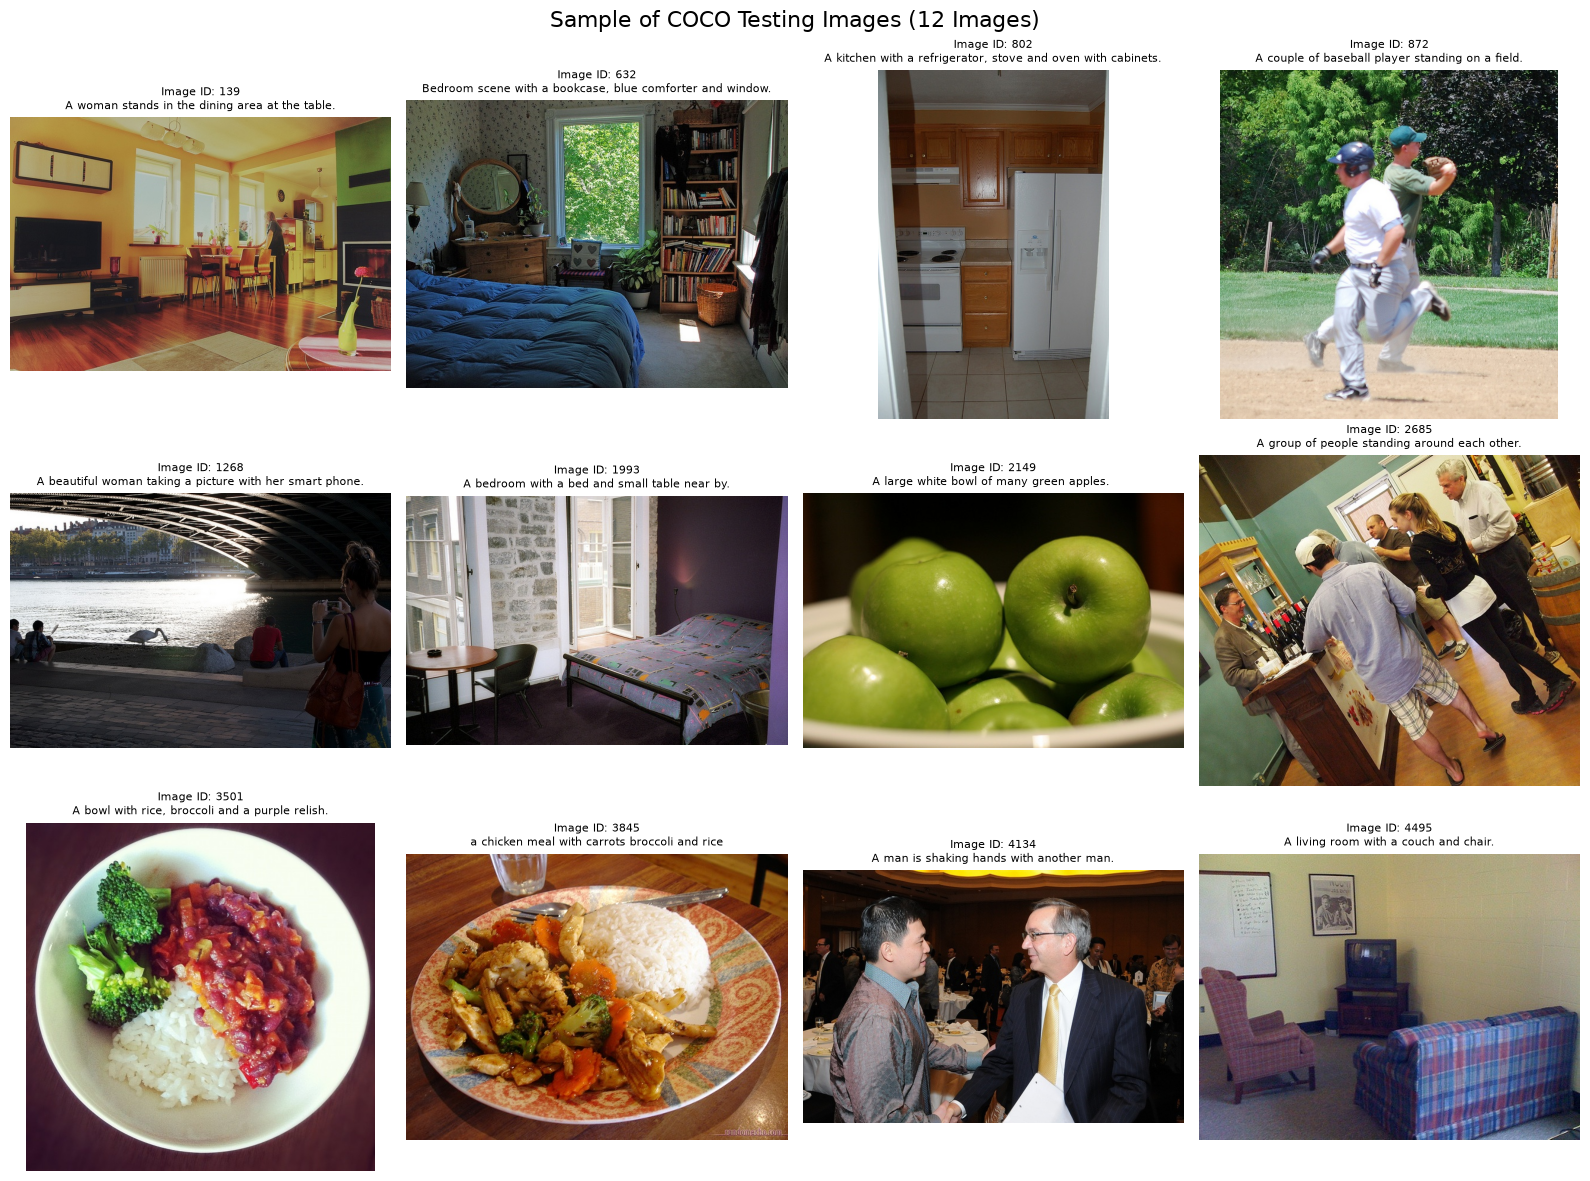

In [37]:
import matplotlib.pyplot as plt
from PIL import Image
import json

sample_df = metadata_df.head(12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_df.iterrows()):

    image = Image.open(row["rgb_path"]).convert("RGB")
    ax.imshow(image)

    captions = json.loads(row["reference_captions"])
    caption = captions[0] if captions else "No caption available"

    ax.set_title(
        f"Image ID: {row['image_id']}\n{caption[:65]}",
        fontsize=8
    )

    ax.axis("off")

plt.suptitle("Sample of COCO Testing Images (12 Images)", fontsize=16)
plt.tight_layout()
plt.show()

## 4.1 RGB and Grayscale Comparison

Compare RGB and grayscale versions of selected testing images.

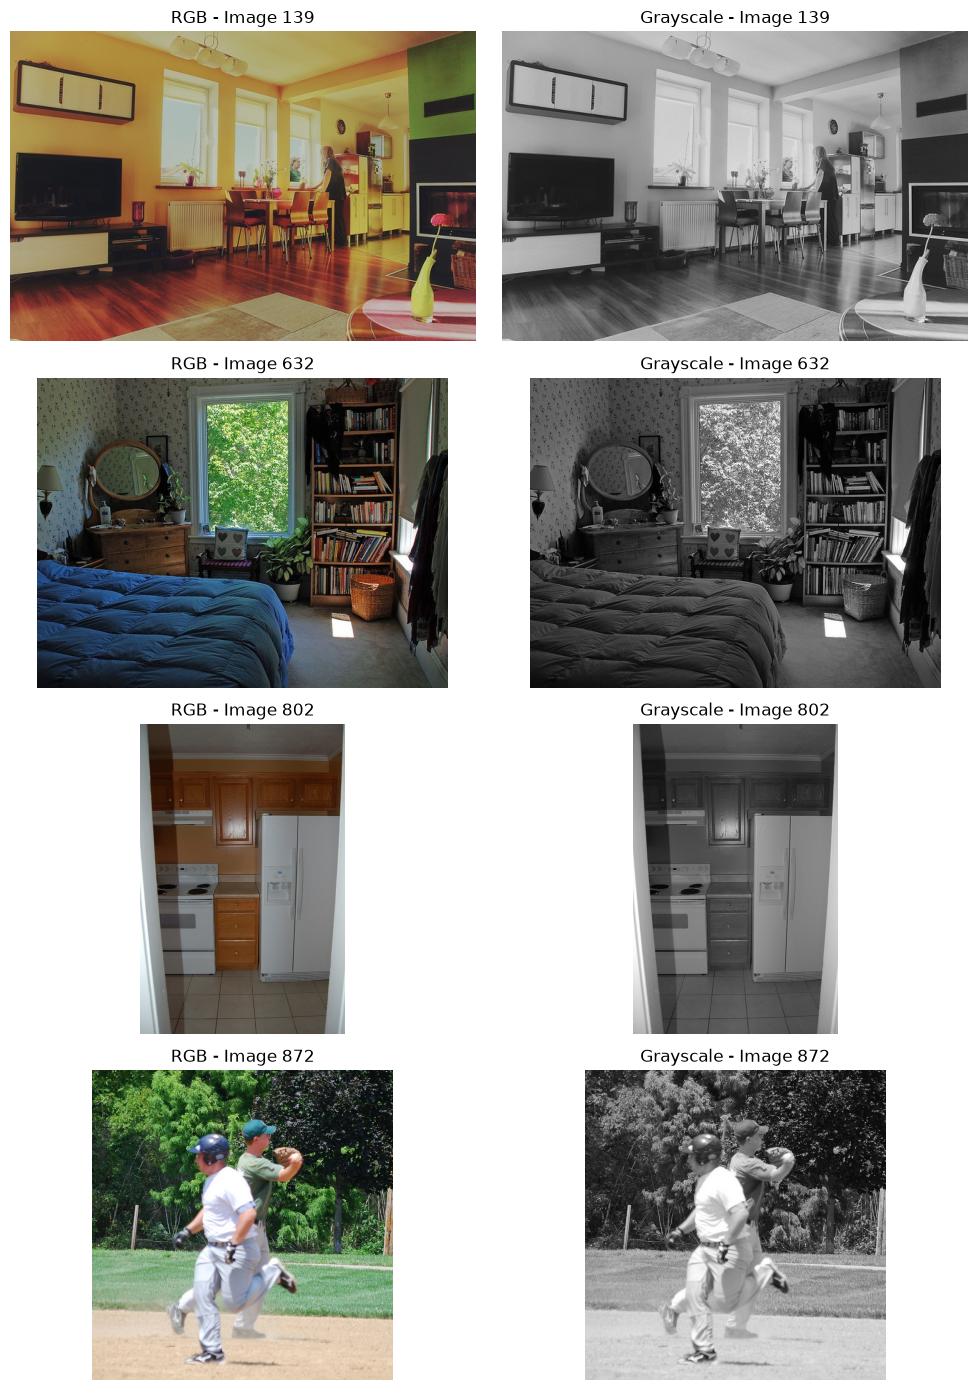

In [38]:
sample_images = metadata_df.head(4)

fig, axes = plt.subplots(4, 2, figsize=(10, 14))

for i, (_, row) in enumerate(sample_images.iterrows()):

    rgb_image = Image.open(row["rgb_path"]).convert("RGB")
    gray_image = Image.open(row["grayscale_path"]).convert("L")

    axes[i, 0].imshow(rgb_image)
    axes[i, 0].set_title(f"RGB - Image {row['image_id']}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gray_image, cmap="gray")
    axes[i, 1].set_title(f"Grayscale - Image {row['image_id']}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### 4.2 Final Verification of Testing Dataset

This final step verifies the completeness and consistency of the testing dataset. It checks the number of original images, metadata records, processed RGB and grayscale images, reference captions, and object annotations.

The objective is to ensure that all 1,000 selected images have been correctly processed and that the generated metadata files are complete and valid.

The testing dataset must remain independent from the training and validation datasets to ensure a reliable and unbiased evaluation of the proposed Metadata-Filtered RAG system.

In [39]:
# Expected dataset size
EXPECTED_IMAGES = 1000

# Count original testing images
original_images = list(TEST_SOURCE_DIR.glob("*.jpg"))

# Count processed images
rgb_images = list(
    (TESTING_DATA_DIR / "testing_images_rgb").glob("*.jpg")
)

grayscale_images = list(
    (TESTING_DATA_DIR / "testing_images_grayscale").glob("*.jpg")
)

# Count metadata records
metadata_count = len(metadata_df)
unique_ids = metadata_df["image_id"].nunique()

# Count original reference captions
reference_caption_count = len(testing_reference_captions)

# Count object annotations
object_annotation_count = len(testing_object_annotations)

# Images without object annotations
images_without_objects = (
    EXPECTED_IMAGES - metadata_df["num_objects"].gt(0).sum()
)

# Verify output files
metadata_exists = (
    TESTING_DATA_DIR / "metadata_testing.csv"
).exists()

ids_exists = (
    TESTING_DATA_DIR / "testing_image_ids.json"
).exists()

# Display results
print("=" * 55)
print("FINAL TESTING DATASET VERIFICATION")
print("=" * 55)

print(f"Expected images: {EXPECTED_IMAGES}")
print(f"Metadata records: {metadata_count}")
print(f"Unique image IDs: {unique_ids}")

print(f"\nOriginal RGB images: {len(original_images)}")
print(f"Processed RGB images: {len(rgb_images)}")
print(f"Processed grayscale images: {len(grayscale_images)}")

print(f"\nOriginal reference captions: {reference_caption_count}")
print(f"Object annotations: {object_annotation_count}")
print(f"Images without object annotations: {images_without_objects}")

print(f"\nMetadata file exists: {metadata_exists}")
print(f"Image IDs file exists: {ids_exists}")

# Final conditions
checks = {
    "Correct number of images": len(original_images) == EXPECTED_IMAGES,
    "Correct metadata records": metadata_count == EXPECTED_IMAGES,
    "Unique image IDs": unique_ids == EXPECTED_IMAGES,
    "All RGB images processed": len(rgb_images) == EXPECTED_IMAGES,
    "All grayscale images processed": len(grayscale_images) == EXPECTED_IMAGES,
    "Metadata file saved": metadata_exists,
    "Image IDs file saved": ids_exists
}

print("\n" + "=" * 55)
print("VERIFICATION RESULTS")
print("=" * 55)

for check, result in checks.items():
    status = "PASS" if result else "FAIL"
    print(f"{check}: {status}")

if all(checks.values()):
    print("\nSUCCESS: Testing dataset is ready for evaluation.")
else:
    print("\nWARNING: Some verification checks failed.")

FINAL TESTING DATASET VERIFICATION
Expected images: 1000
Metadata records: 1000
Unique image IDs: 1000

Original RGB images: 1000
Processed RGB images: 1000
Processed grayscale images: 1000

Original reference captions: 5002
Object annotations: 7375
Images without object annotations: 10

Metadata file exists: True
Image IDs file exists: True

VERIFICATION RESULTS
Correct number of images: PASS
Correct metadata records: PASS
Unique image IDs: PASS
All RGB images processed: PASS
All grayscale images processed: PASS
Metadata file saved: PASS
Image IDs file saved: PASS

SUCCESS: Testing dataset is ready for evaluation.
